# 01 · Análise exploratória do trânsito de São Paulo

**Pergunta de ML:** dado o horário, o dia da semana, a lentidão atual e as ocorrências registradas, qual será a lentidão do trânsito de São Paulo na próxima janela de 30 minutos? Com essa previsão o Semáforo Inteligente ajusta o tempo de verde *antes* do congestionamento se formar.

**Fonte (real e pública):** UCI Machine Learning Repository, dataset 483, *Behavior of the urban traffic of the city of São Paulo in Brazil*, com dados da CET-SP. https://archive.ics.uci.edu/dataset/483

**Período:** 14/12/2009 (segunda) a 18/12/2009 (sexta), das 7h00 às 20h00, em janelas de 30 minutos (135 registros).

Este notebook só **olha** os dados. A limpeza e a criação de variáveis ficam no `02_preparacao.ipynb`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Arquivo original da CET/UCI: separador ';' e decimal ','
bruto = pd.read_csv('dados/bruto/sp_trafego_uci_2009.csv', sep=';', decimal=',')
print(bruto.shape)
bruto.head()

(135, 18)


,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.1
1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.6
2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.7
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.2
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11.1


In [2]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Hour (Coded)                           135 non-null    int64  
 1   Immobilized bus                        135 non-null    int64  
 2   Broken Truck                           135 non-null    int64  
 3   Vehicle excess                         135 non-null    int64  
 4   Accident victim                        135 non-null    int64  
 5   Running over                           135 non-null    int64  
 6   Fire vehicles                          135 non-null    int64  
 7   Occurrence involving freight           135 non-null    int64  
 8   Incident involving dangerous freight   135 non-null    int64  
 9   Lack of electricity                    135 non-null    int64  
 10  Fire                                   135 non-null    int64  
 11  Point of flooding

## Tradução das colunas e reconstrução da data/hora
O arquivo traz só a hora codificada (1 = 7h00 … 27 = 20h00). Reconstruímos a data e a hora para poder analisar o comportamento ao longo do dia.

In [3]:
RENOMEAR = {
    'Hour (Coded)': 'janela', 'Immobilized bus': 'onibus_parado', 'Broken Truck': 'caminhao_quebrado',
    'Vehicle excess': 'excesso_veiculos', 'Accident victim': 'acidente_com_vitima', 'Running over': 'atropelamento',
    'Fire vehicles': 'incendio_veiculo', 'Occurrence involving freight': 'ocorrencia_carga',
    'Incident involving dangerous freight': 'carga_perigosa', 'Lack of electricity': 'falta_energia',
    'Fire': 'incendio', 'Point of flooding': 'ponto_alagamento', 'Manifestations': 'manifestacao',
    'Defect in the network of trolleybuses': 'defeito_rede_trolebus', 'Tree on the road': 'arvore_na_via',
    'Semaphore off': 'semaforo_apagado', 'Intermittent Semaphore': 'semaforo_intermitente',
    'Slowness in traffic (%)': 'lentidao_pct',
}
OCORRENCIAS = [c for c in RENOMEAR.values() if c not in ('janela', 'lentidao_pct')]
DIAS = ['segunda', 'terca', 'quarta', 'quinta', 'sexta']

df = bruto.rename(columns=RENOMEAR)
# As linhas estão em ordem cronológica: 5 dias úteis x 27 janelas de 30 min (7h00 a 20h00),
# começando na segunda 14/12/2009.
dia_idx = df.index // 27
df['timestamp'] = (pd.Timestamp('2009-12-14 07:00')
                   + pd.to_timedelta(dia_idx, unit='D')
                   + pd.to_timedelta((df['janela'] - 1) * 30, unit='min'))
df['dia_semana'] = df['timestamp'].dt.dayofweek.map(dict(enumerate(DIAS)))
df['hora_decimal'] = df['timestamp'].dt.hour + df['timestamp'].dt.minute / 60
df[['timestamp', 'dia_semana', 'janela', 'lentidao_pct']].head()

,timestamp,dia_semana,janela,lentidao_pct
0,2009-12-14 07:00:00,segunda,1,4.1
1,2009-12-14 07:30:00,segunda,2,6.6
2,2009-12-14 08:00:00,segunda,3,8.7
3,2009-12-14 08:30:00,segunda,4,9.2
4,2009-12-14 09:00:00,segunda,5,11.1


## Qualidade dos dados

In [4]:
print('Valores ausentes:', df.isna().sum().sum())
print('Linhas duplicadas:', df.duplicated().sum())
print('Janelas por dia:', df.groupby('dia_semana', sort=False).size().to_dict())
df['lentidao_pct'].describe().round(2)

Valores ausentes: 0
Linhas duplicadas: 0
Janelas por dia: {'segunda': 27, 'terca': 27, 'quarta': 27, 'quinta': 27, 'sexta': 27}


count    135.00
mean      10.05
std        4.36
min        3.40
25%        7.40
50%        9.00
75%       11.85
max       23.40
Name: lentidao_pct, dtype: float64

## Distribuição da variável alvo (`lentidao_pct`)

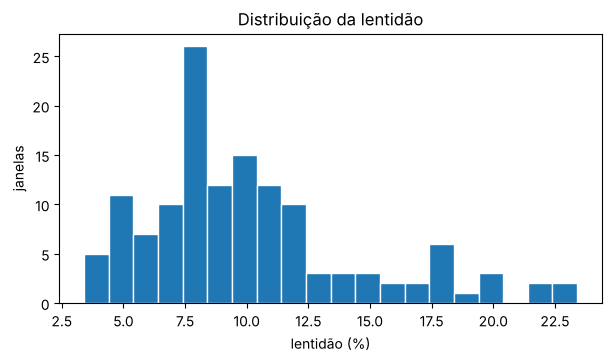

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df['lentidao_pct'], bins=20, edgecolor='white')
ax.set(xlabel='lentidão (%)', ylabel='janelas', title='Distribuição da lentidão')
plt.show()

## Lentidão ao longo do dia
Aparecem os dois picos: um leve de manhã (8h–9h) e um forte no fim da tarde (18h–19h30).

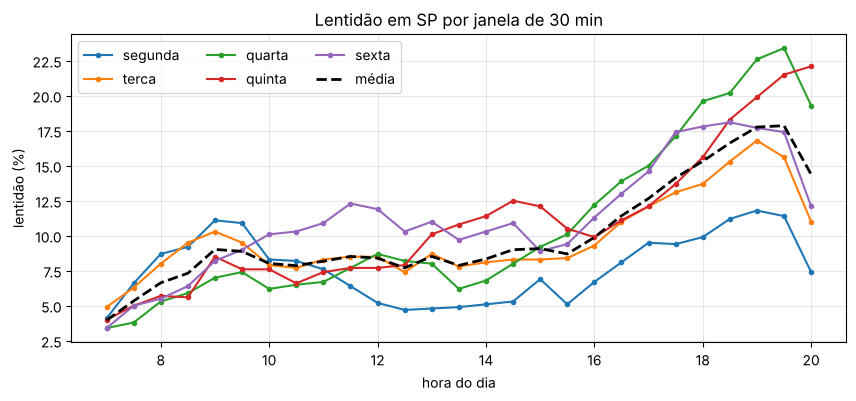

timestamp,7,8,9,10,11,12,13,14,15,16,17,18,19,20
lentidao_media_pct,4.6,7.0,9.0,7.9,8.4,8.0,8.2,8.7,8.9,10.6,13.4,16.0,17.8,14.4


In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for dia, g in df.groupby('dia_semana', sort=False):
    ax.plot(g['hora_decimal'], g['lentidao_pct'], marker='o', ms=3, label=dia)
media = df.groupby('hora_decimal')['lentidao_pct'].mean()
ax.plot(media.index, media.values, 'k--', lw=2, label='média')
ax.set(xlabel='hora do dia', ylabel='lentidão (%)', title='Lentidão em SP por janela de 30 min')
ax.legend(ncol=3); ax.grid(alpha=.3); plt.show()
df.groupby(df['timestamp'].dt.hour)['lentidao_pct'].mean().round(1).to_frame('lentidao_media_pct').T

## Lentidão por dia da semana

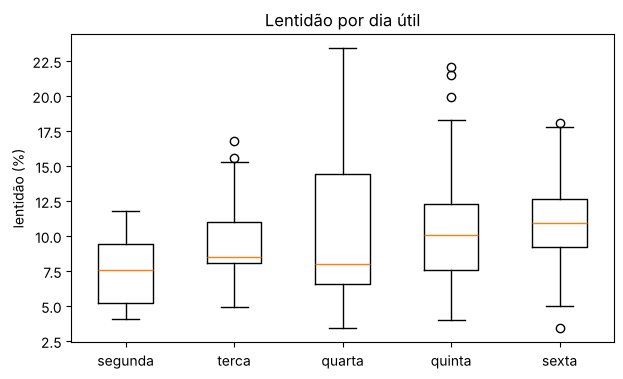

,mean,max
dia_semana,,
segunda,7.7,11.8
terca,9.8,16.8
quarta,10.7,23.4
quinta,10.8,22.1
sexta,11.2,18.1


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df['dia_semana'] == d, 'lentidao_pct'] for d in DIAS], tick_labels=DIAS)
ax.set(ylabel='lentidão (%)', title='Lentidão por dia útil'); plt.show()
df.groupby('dia_semana', sort=False)['lentidao_pct'].agg(['mean', 'max']).round(1)

## Ocorrências
Quais ocorrências mais acontecem e como a lentidão muda quando há falha de semáforo.

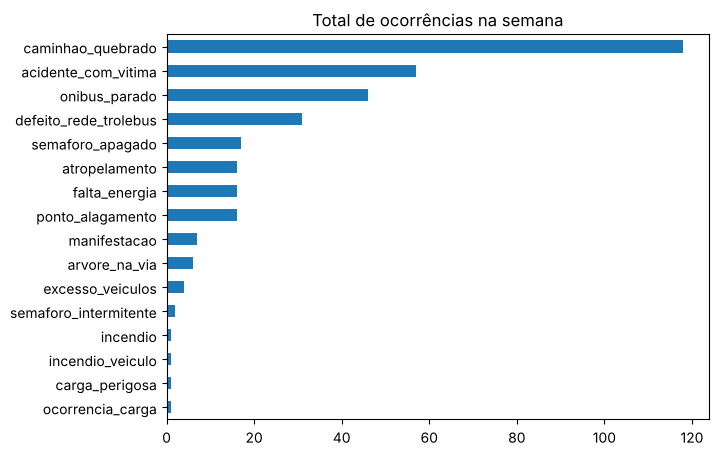

sem falha de semáforo     9.69
com falha de semáforo    12.93
Name: lentidao_pct, dtype: float64

In [8]:
df[OCORRENCIAS].sum().sort_values().plot.barh(figsize=(7, 5), title='Total de ocorrências na semana')
plt.show()
falha = (df['semaforo_apagado'] + df['semaforo_intermitente']) > 0
df.groupby(falha)['lentidao_pct'].mean().rename({False: 'sem falha de semáforo', True: 'com falha de semáforo'}).round(2)

## Autocorrelação: a janela anterior explica a próxima?

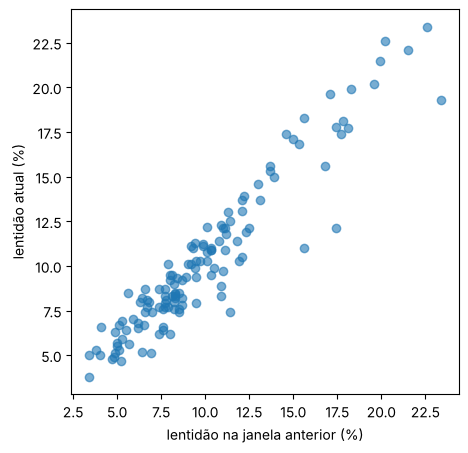

Correlação: 0.946


In [9]:
anterior = df.groupby('dia_semana', sort=False)['lentidao_pct'].shift(1)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(anterior, df['lentidao_pct'], alpha=.6)
ax.set(xlabel='lentidão na janela anterior (%)', ylabel='lentidão atual (%)')
plt.show()
print('Correlação:', round(anterior.corr(df['lentidao_pct']), 3))

## Correlação das variáveis com a lentidão

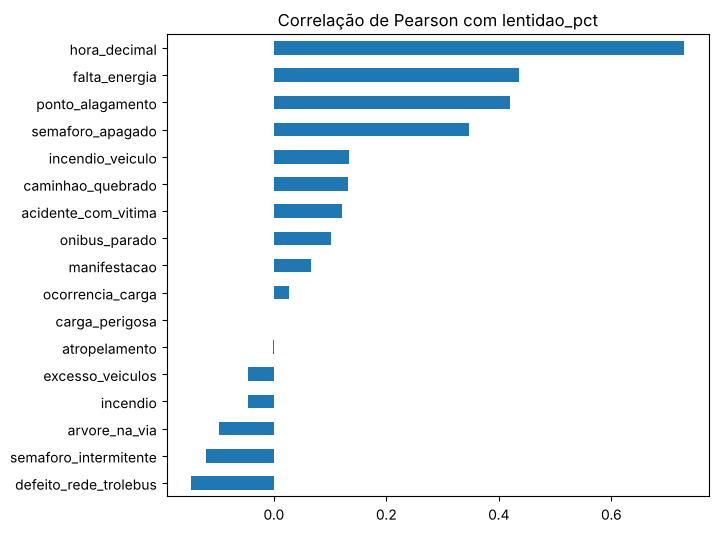

In [10]:
corr = df[OCORRENCIAS + ['hora_decimal', 'lentidao_pct']].corr()['lentidao_pct'].drop('lentidao_pct').sort_values()
corr.plot.barh(figsize=(7, 6), title='Correlação de Pearson com lentidao_pct'); plt.show()

## Conclusões da exploração

- **Sem ausentes nem duplicados**, 27 janelas em cada um dos 5 dias.
- **O horário é o fator dominante:** a lentidão média sai de cerca de 4,6% às 7h para 17,8% às 19h.
- **A semana piora até a sexta**; a segunda é o dia mais leve.
- **A janela anterior explica muito da atual** (correlação ≈ 0,95). Vamos criar essa variável na preparação.
- **Falha de semáforo coincide com mais lentidão** (≈ 9,7% sem falha contra 12,9% com falha), o que reforça o valor de semáforos monitorados.
- Ocorrências como alagamento, falta de energia e semáforo apagado são raras, mas aparecem nos momentos mais lentos.
- **Limitação:** são só 5 dias úteis. Isso guia a divisão treino/teste do próximo notebook.